Simulating the Double Slit Experiment with Qrisp
=================================================

The double slit experiment is one of the most famous experiments in all of physics.
A particle — an electron, a photon, even a whole molecule — is fired at a barrier that has two narrow openings (slits).
Classically you would expect the particle to go through one slit or the other and leave two bright bands on a detector screen behind the barrier.
What is actually observed is something completely different: an **interference pattern** of many alternating bright and dark fringes, as if the particle were a wave passing through both slits simultaneously and interfering with itself.

This wave-like behaviour is captured by the particle's **wave function**: a complex amplitude $\psi(x)$ spread across all positions.
Each slit acts as a secondary wave source; the two contributions overlap and their amplitudes add — constructively at some screen positions (bright fringes) and destructively at others (dark fringes).
According to the **Fraunhofer diffraction** formula, the far-field intensity pattern is the squared magnitude of the Fourier transform of the aperture function $A(x)$:

$$I(k) \;\propto\; \left|\,\hat{A}(k)\,\right|^2 = \left|\sum_x A(x)\, e^{-i 2\pi k x / N}\right|^2$$

where $A(x) = 1$ inside the slits and $0$ everywhere else.

### Mapping the experiment to a quantum algorithm

This Fourier relationship has a direct quantum analogue, and we can simulate the whole experiment with three steps:

**Step 1 — Prepare the slit state.**  
We encode the particle's position as a quantum integer and prepare a superposition over exactly those positions that lie inside the slits — and zero amplitude everywhere else:

$$|\text{slit}\rangle = \frac{1}{\sqrt{M}} \sum_{x \in \text{slits}} |x\rangle$$

This encodes the aperture function $A(x)$ directly as quantum amplitudes.
We will prepare it using **Grover's algorithm**.

**Step 2 — Steer the beam.**  
A linear phase ramp $e^{i k_0 x}$ applied qubit-by-qubit shifts the diffraction pattern to a chosen observation angle. This is done with single-qubit **phase gates**.

**Step 3 — Observe the far field.**  
The **Quantum Fourier Transform** maps position amplitudes to spatial-frequency amplitudes — exactly the Fraunhofer integral. Measuring the register then samples from the intensity pattern $P(k) = |\hat{A}(k)|^2$.

You will implement each building block as a small, self-contained exercise and assemble them into the full simulation at the end.

<div style="display:flex; gap:32px; align-items:flex-start; flex-wrap:wrap; margin-top:12px;">

<div style="text-align:center; flex:1; min-width:260px;">

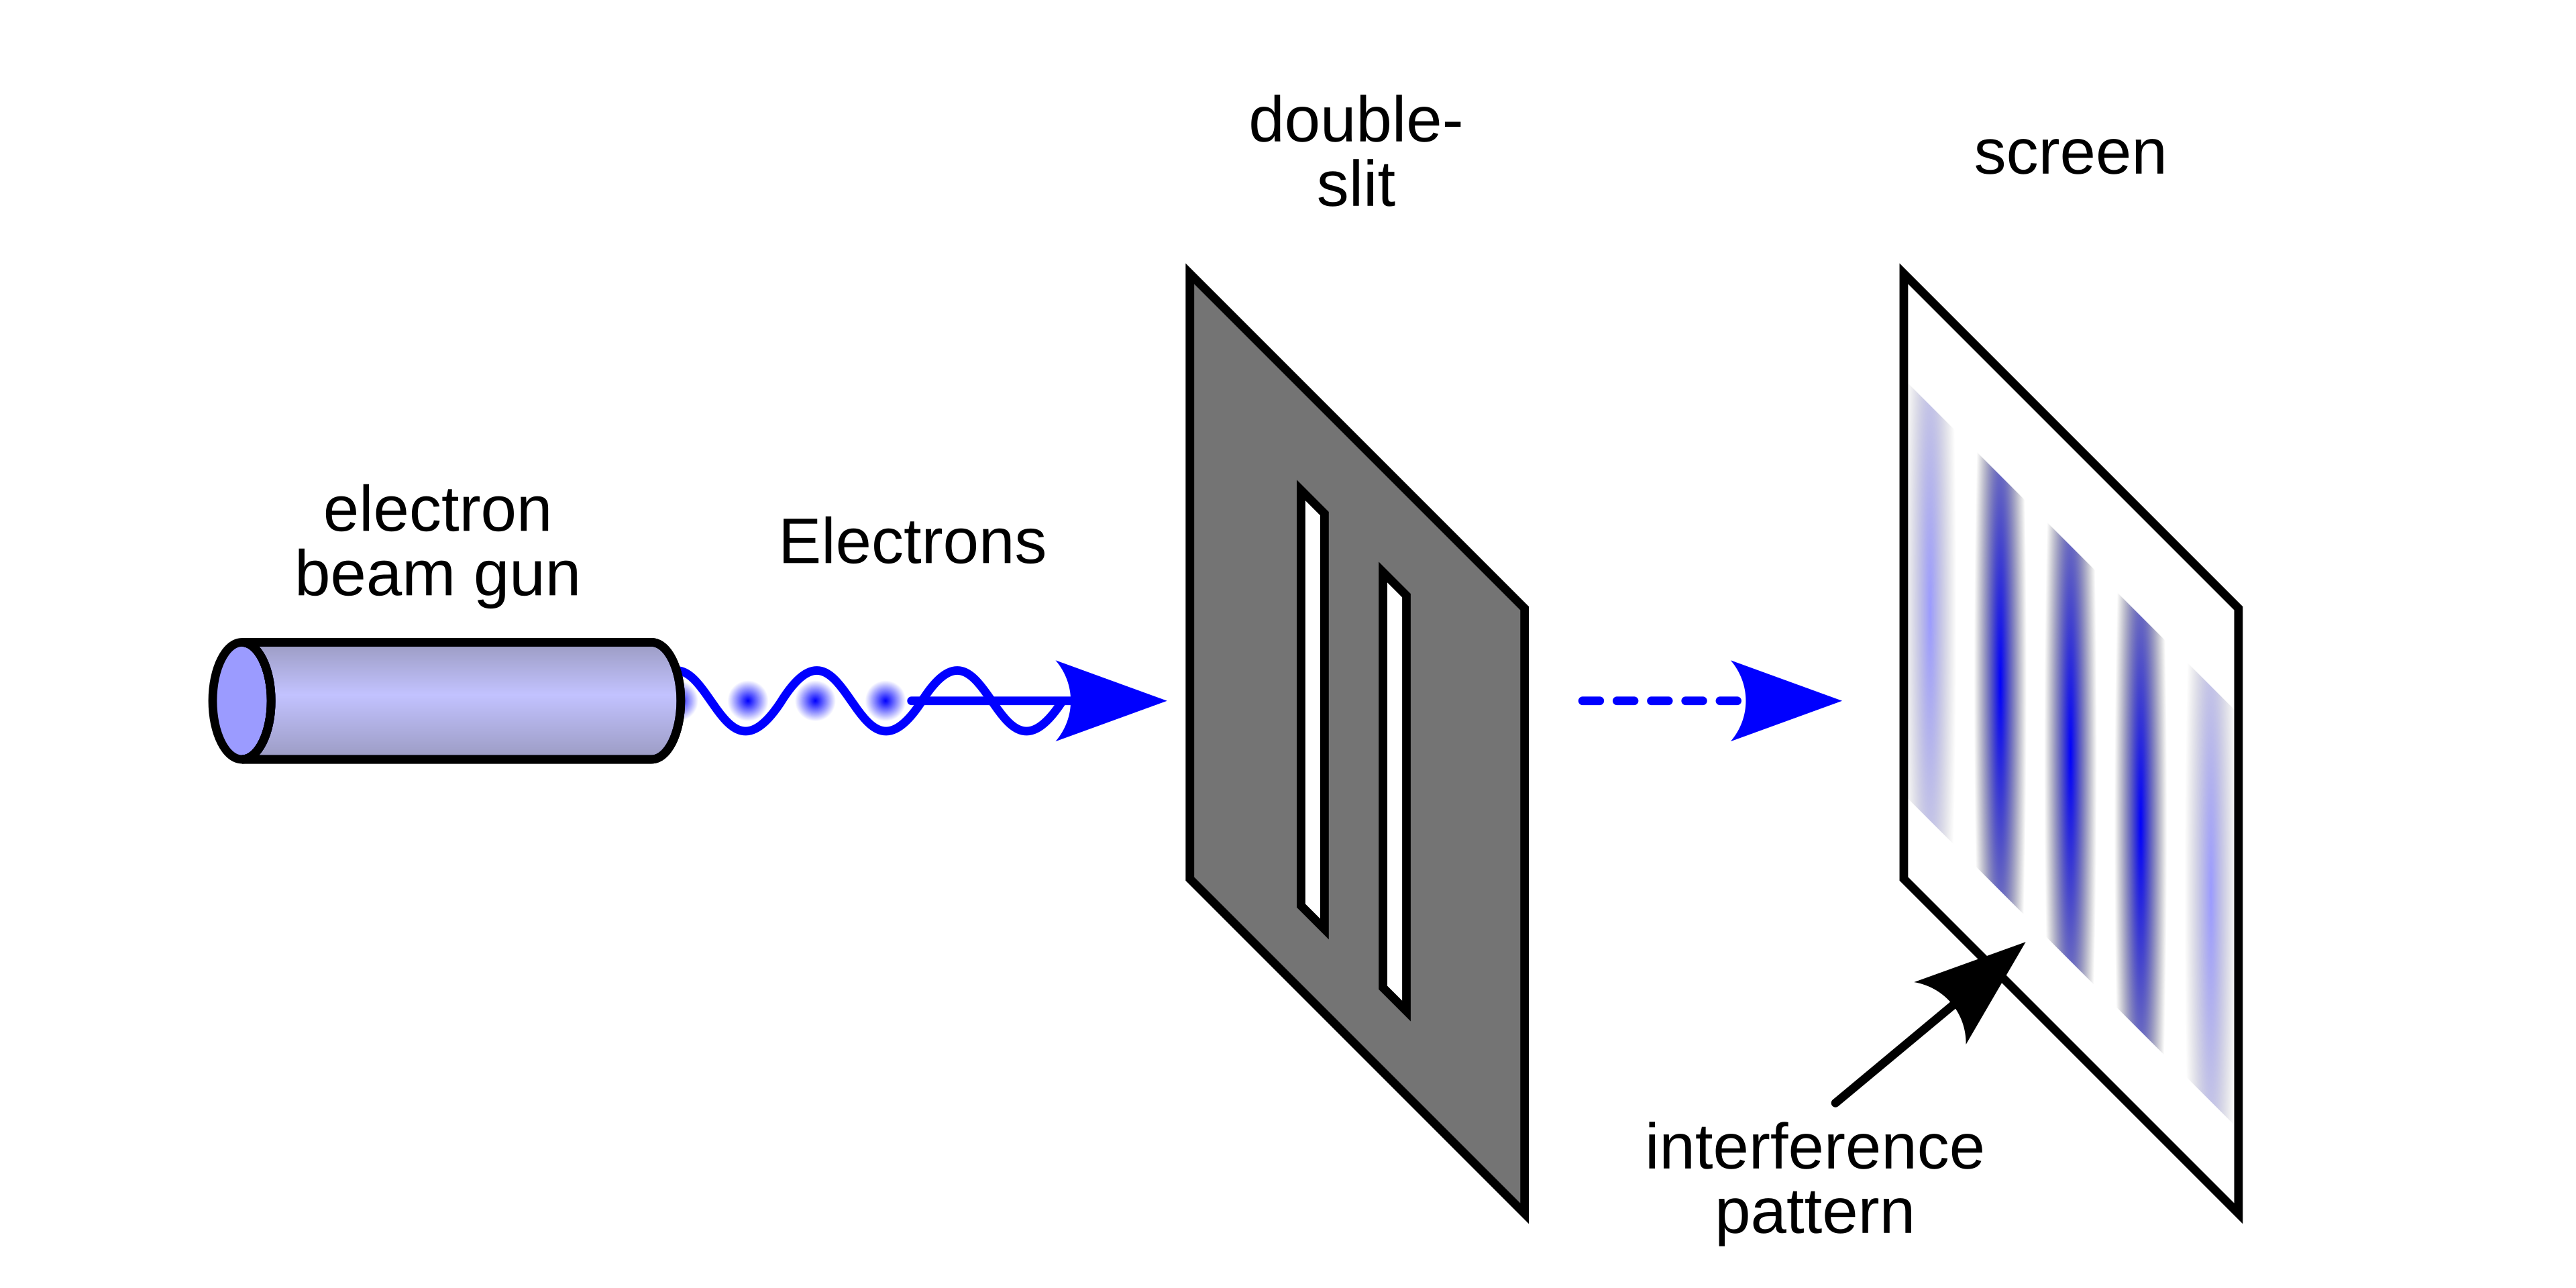

*Fig. 1 — Double-slit experiment schematic: particle source, barrier with two openings, and the interference pattern on the detection screen.*

</div>

<div style="text-align:center; flex:1; min-width:260px;">

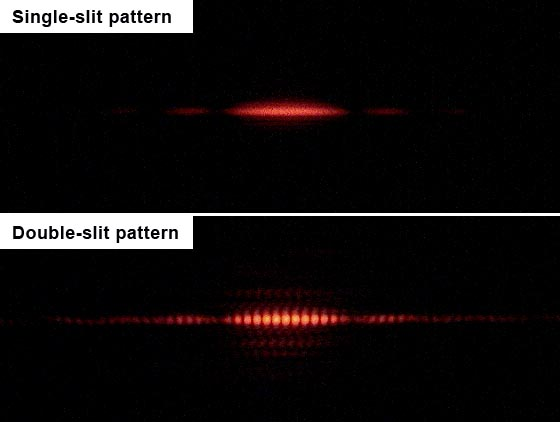

*Fig. 2 — Laser photographs (0.7 mm slit spacing). **Top:** one slit open — broad single-peak envelope. **Bottom:** both slits open — fine fringes appear inside the envelope.*

</div>

</div>

> Images: Wikipedia / Wikimedia Commons, CC BY-SA

<div style="text-align:center; flex:1; min-width:260px;">

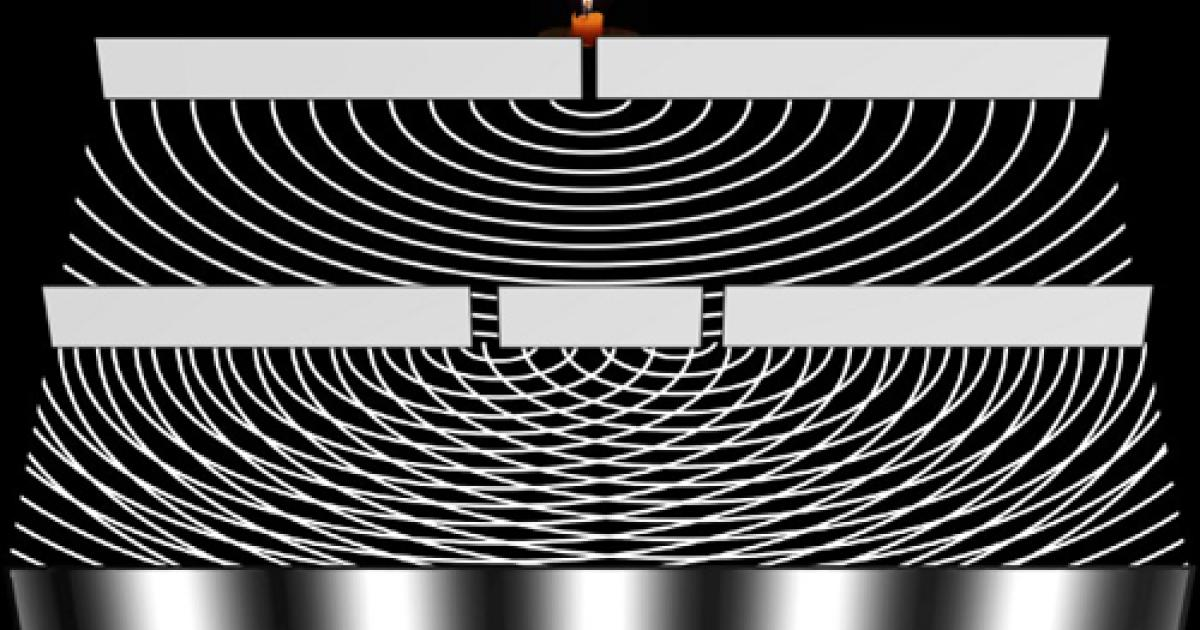

*Fig. 3 — Superposition of two circular waves from separate point sources (the two slits). Where crests meet crests, the amplitude adds constructively (bright fringes); where a crest meets a trough, they cancel (dark fringes).*

</div>

> [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Doubleslit3Dspectrum.gif), CC BY-SA

## 0. Setup

If you don't have Qrisp installed yet, uncomment and run the cell below.

**Qrisp** is a high-level quantum programming framework. If you're coming from Qiskit, the key difference is that Qrisp lets you write quantum programs using Python-native constructs (arithmetic operators, comparisons, typed variables) rather than manually assembling gates onto circuits.

📖 **Documentation**: [https://www.qrisp.eu/reference/](https://www.qrisp.eu/reference/) — you'll find API references for every function used in this tutorial there.

In [ ]:
# Uncomment the line below if Qrisp is not yet installed:
# !pip install qrisp

In [ ]:
%matplotlib inline

from collections.abc import Callable, Mapping

from qrisp import *
from qrisp.grover import grovers_alg
import numpy as np
import matplotlib.pyplot as plt

## 1. The Particle Position: [`QuantumFloat`](https://www.qrisp.eu/reference/Quantum%20Types/QuantumFloat.html)

The particle's position at the barrier is encoded as a quantum integer.
[`QuantumFloat(n)`](https://www.qrisp.eu/reference/Quantum%20Types/QuantumFloat.html) creates an `n`-qubit register that can store unsigned integers $0 \ldots 2^n - 1$.
With 5 qubits we get 32 discrete positions — more than enough to place two slits.

```
positions:  0  1  …  12  13  14  15  16  17  18  19  20  21  22  23  24  …  31
                          ↑--- slit 1 ---↑        ↑--- slit 2 ---↑
```

Creating a `QuantumFloat` is straightforward:

In [ ]:
# A QuantumFloat with 5 qubits represents integers 0 … 31.
qf = QuantumFloat(5)

# Calling print triggers a simulation and shows the measurement probabilities.
# A freshly created QuantumFloat is in the |0> state.
print("Initial state:")
print(qf)

# Assign a classical value using the slice operator.
qf[:] = 14
print("After qf[:] = 14:")
print(qf)

# Applying a Hadamard gate h() to ALL qubits creates uniform superposition over 0 … 31.
# Docs: https://www.qrisp.eu/reference/Primitives/generated/qrisp.h.html
h(qf)
print("After h(qf) — uniform superposition:", qf)

## 2. Preparing the Slit State with Grover's Algorithm

We just saw that `h(qf)` puts *all* 32 positions into equal superposition.
That is the wave before the barrier — it does not know about the slits yet.
What we actually want is a state where only the slit positions carry amplitude:

$$|\text{slit}\rangle = \frac{1}{\sqrt{M}} \sum_{x \in \text{slits}} |x\rangle, \qquad M = \text{number of open positions}$$

How do we get there? We use **[Grover's algorithm](https://www.qrisp.eu/reference/Algorithms/Grover.html)**.

### Grover's algorithm in a nutshell

Grover's algorithm starts from the uniform superposition $h(\text{qf})$ and, by repeatedly applying two operations, amplifies the amplitudes of a chosen set of *winner* states while suppressing all others:

1. **Oracle** — A quantum function that recognises winner states and applies a phase shift $e^{i\phi}$ to them (leaving all other states unchanged).  It does *not* collapse the superposition — it only rotates phases.
2. **Diffuser** — Reflects the state around the average amplitude, which turns the phase difference introduced by the oracle into an amplitude boost for the winners.

After enough iterations the winners dominate the state.  The **exact** variant of Grover's algorithm (which we will use) can be tuned to set the winner amplitudes to *exactly* $1/\sqrt{M}$ and all loser amplitudes to *exactly* zero — no approximation.

### What does the oracle need to do here?

For our simulation the winners are the positions *inside* the slits.  The oracle therefore needs to answer the question:

> "Is this position inside any of the slits?"

To answer that question *in superposition* — i.e. for all 32 positions simultaneously — we must express the slit-membership check as quantum logic.  That is what the next sections are about: we first build a function `is_in_slit` that computes a `QuantumBool` answer for a single slit, then combine those answers in the oracle for all slits.

## 3. Quantum Comparisons — Turning a Position into a Boolean

A slit is defined by two boundaries: a lower bound and an upper bound.
A position $x$ is *inside* the slit when both conditions hold simultaneously:

$$x \geq \text{lower} \quad \text{AND} \quad x < \text{upper}$$

This is the standard half-open interval $[\text{lower},\, \text{upper})$, the same convention used by Python's `range(lower, upper)`.

In Qrisp, comparison operators on a `QuantumFloat` return a **[`QuantumBool`](https://www.qrisp.eu/reference/Quantum%20Types/QuantumBool.html)** — a 1-qubit variable that is `True` or `False` in superposition:

```python
above_lower = qf >= lower   # QuantumBool
below_upper = qf < upper    # QuantumBool
```

To combine two `QuantumBool`s with a logical AND we use **[`mcx`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.mcx.html)** — short for **Multi-Controlled X**.
Breaking the name down:
- **X** is the quantum NOT gate (also called the Pauli-X gate): it flips a qubit from $|0\rangle$ to $|1\rangle$ and vice versa.
- **Multi-Controlled** means the flip is *conditional* — it only fires when **all** specified control qubits are in state $|1\rangle$.

So `mcx([a, b], target)` flips `target` only when both `a` and `b` are `True`, which is exactly a quantum AND:

$$\text{target} \mathrel{\oplus}= a \;\text{AND}\; b$$

```python
result = QuantumBool()
mcx([above_lower, below_upper], result)   # result = above_lower AND below_upper
```

Here is a quick demo on a concrete position:

In [ ]:
lower, upper = 13, 16   # first slit: positions 13, 14, 15

# Try the two boundary conditions for position 14 (inside the slit).
qf_demo = QuantumFloat(5)
qf_demo[:] = 14

above_lower = qf_demo >= lower   # True: 14 >= 13
below_upper = qf_demo < upper    # True: 14 < 16

print(f"qf_demo = {qf_demo.get_measurement()}")
print(f"qf_demo >= {lower}  →  {above_lower}")
print(f"qf_demo < {upper} →  {below_upper}")

# Combine them with AND
result = QuantumBool()
mcx([above_lower, below_upper], result)
print(f"AND of both conditions → {result}")  # Should be {{True: 1.0}}

### Exercise: `is_in_slit`

Now package the logic above into a reusable function.

`is_in_slit(qf, slit)` receives:
- `qf` — a `QuantumFloat` representing the particle's position
- `slit` — a classical tuple `(lower, upper)` defining one slit

and returns a `QuantumBool` that is `True` exactly when the position is inside the slit, i.e. when `lower <= qf < upper`.

In [ ]:
def is_in_slit(qf: QuantumFloat, slit: tuple[int, int]) -> QuantumBool:
    """
    Computes whether the quantum position qf lies inside the given slit.

    A position x is "inside" when  lower <= x < upper  (half-open interval).

    Parameters
    ----------
    qf   : QuantumFloat
        The quantum position register.
    slit : tuple (lower, upper)
        Classical integers defining the slit boundaries.

    Returns
    -------
    QuantumBool
        True iff qf is inside the slit.
    """
    lower, upper = slit

    # TO-DO
    # 1. Compute QuantumBools for the two boundary conditions (use >= and <).
    # 2. Create a result QuantumBool and use mcx to compute their AND.
    # 3. Return the result.

    pass

In [ ]:
# --- Test is_in_slit ---
# We put the position register into a full superposition and measure (qf, in_slit) jointly.
# Every position that lies inside the slit should show True, all others False.

slit_under_test = (13, 16)   # positions 13, 14, 15

qf_test = QuantumFloat(5)
h(qf_test)                                    # all 32 positions in superposition

in_slit_test = is_in_slit(qf_test, slit_under_test)

joint = multi_measurement([qf_test, in_slit_test])

errors = []
for (pos, flag), prob in joint.items():
    expected = slit_under_test[0] <= pos < slit_under_test[1]
    if flag != expected:
        errors.append(f"  position {pos}: got {flag}, expected {expected}")

if errors:
    print("Something is wrong:")
    for e in errors:
        print(e)
else:
    print("Congratulations! is_in_slit works correctly.")

## 4. The Slit Oracle

Grover's algorithm uses an **oracle**: a quantum function that applies a phase shift $e^{i\phi}$ to every *winner* state and leaves all other states unchanged.
In our case the winner states are the positions inside any slit.

Two new building blocks are needed here.

### 4.1 Phase gate [`p(phase, qubit)`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.p.html)

[`p(phase, qubit)`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.p.html) applies the rotation $|1\rangle \mapsto e^{i\,\text{phase}}|1\rangle$ to a single qubit.
When `qubit` is actually a `QuantumBool` that is `True` iff the position is a winner, the gate effectively phase-tags all winner states.

### 4.2 Computing OR across multiple slits

For a barrier with more than one slit we need:

```
result = is_in_slit_0  OR  is_in_slit_1  OR  …
```

You might wonder: why not just use a direct OR gate? Unlike classical logic, quantum hardware doesn't have a built-in OR — only controlled operations (AND-like gates) are native. So we reach for a classic trick from Boolean algebra: **De Morgan's law** lets us express OR in terms of AND and NOT:

$$A \lor B = \lnot(\lnot A \land \lnot B)$$

In Qrisp, `mcx([a, b], target, ctrl_state=0)` fires when *all* controls are `|0⟩`, i.e. when *none* of the conditions is `True` — this computes "NOT (A OR B)". After flipping `result` with `result.flip()` we negate that, giving us the correct OR value.

### 4.3 Automatic uncomputation

The boundary comparisons and per-slit booleans are *ancilla* qubits — they were needed to produce the phase tag, but they must be reset to $|0\rangle$ afterwards.
If they remain entangled with `qf`, the superposition of different slit paths can no longer interfere and Grover's algorithm breaks.

The [`@auto_uncompute`](https://www.qrisp.eu/reference/Core/Uncomputation.html) decorator handles this automatically.
It analyses the data-flow in the function and appends the exact inverse operations to disentangle every locally created `QuantumVariable` before the function returns — exactly like the physical requirement of erasing which-path information to restore interference.

> 💡 **Try it yourself**: Remove `@auto_uncompute` from `slit_oracle` and run the Grover cell. Qrisp refuses with `Tried to invoke IterationEnvironment with code creating/deleting QuantumVariables`: the oracle leaves its ancilla variables behind, still entangled with the position register.

### Exercise: `slit_oracle`

Implement `slit_oracle(qf, slits, phase)` using `is_in_slit`.
The function should:

1. Call `is_in_slit` once for each slit and collect the resulting `QuantumBool`s.
2. Compute a single `result` `QuantumBool` that is `True` when *any* slit matched (OR logic via De Morgan: `mcx(..., ctrl_state=0)` + `result.flip()`).
3. Phase-tag the winner states with `p(phase, result)`.
4. Let [`@auto_uncompute`](https://www.qrisp.eu/reference/Core/Uncomputation.html) clean up all intermediate qubits.

In [ ]:
@auto_uncompute
def slit_oracle(qf: QuantumFloat, slits: list[tuple[int, int]], phase: float) -> None:
    """
    Phase-tags every computational basis state |x> that lies inside any slit.

    Parameters
    ----------
    qf    : QuantumFloat   — the position register
    slits : list of (lower, upper) tuples — barrier geometry
    phase : float          — phase applied to winner states
    """

    # TO-DO
    # Step 1: Call is_in_slit for each slit and collect the QuantumBools.

    # TO-DO
    # Step 2: Compute OR via De Morgan.
    #   mcx(inside_qbls, result, ctrl_state=0) fires when ALL controls are |0>,
    #   i.e. when the position is OUTSIDE every slit.
    #   result.flip() inverts this, so result==True means "inside at least one slit".

    # TO-DO
    # Step 3: Apply the phase only to states where result is True.

    pass

    # @auto_uncompute will uncompute inside_qbls and result automatically.

## 5. The Slit State via Exact Grover's Algorithm

We want to prepare the **slit state** — a uniform superposition over slit positions only:

$$|\text{slit}\rangle = \frac{1}{\sqrt{M}} \sum_{x \in \text{slits}} |x\rangle, \qquad M = \text{total open positions}$$

Starting from $h(\text{qf})$ (all 32 positions equally likely) we need to zero out the 26 positions that are blocked by the barrier while keeping the 6 slit positions with exactly equal amplitude. This is exactly the kind of *amplitude amplification* task that Grover's algorithm was designed for.

### Standard Grover vs. Exact Grover

**Standard Grover's algorithm** works by iterating two steps:

1. **Oracle** — applies a phase of $e^{i\pi} = -1$ to every winner state (a sign flip): $|x\rangle \to -|x\rangle$ for $x \in \text{winners}$.
2. **Diffuser** — reflects the full state around the average amplitude.

Each iteration rotates the state vector by a fixed angle $\theta$ in the 2D plane spanned by the uniform superposition and the target state. After $k \approx \frac{\pi}{4}\sqrt{N/M}$ iterations the winners dominate. However, because this angle is fixed and $k$ must be an integer, the algorithm **overshoots or undershoots** slightly — the winners are not amplified to exactly $1/\sqrt{M}$ and the losers are not suppressed to exactly $0$. For a quantum simulation that is meant to represent *precisely* the slit aperture this residual contamination from blocked positions is unacceptable.

**Exact Grover's algorithm** ([Long 2001](https://arxiv.org/pdf/quant-ph/0106071.pdf), [Qrisp docs](https://www.qrisp.eu/reference/Algorithms/Grover.html)) fixes this by using a **non-$\pi$ phase angle** in both the oracle and the diffuser:

$$\phi = 2 \arcsin\!\left(\sin\!\frac{\pi}{4k+2} \cdot \sqrt{\frac{N}{M}}\right)$$

where $k = \left\lceil \frac{\pi}{4\theta} - \frac{1}{2} \right\rceil$ is the number of iterations and $\sin\theta = \sqrt{M/N}$.

With this choice the rotation per iteration is tuned so that after exactly $k$ steps the state lands *perfectly* on the target — winner amplitudes are exactly $\frac{1}{\sqrt{M}}$ and all loser amplitudes are exactly $0$.

### How the oracles differ

| | Standard Grover | Exact Grover |
|---|---|---|
| Phase applied to winners | $e^{i\pi} = -1$ (hardcoded sign flip) | $e^{i\phi}$ with $\phi$ computed from $N$, $M$, $k$ |
| Oracle signature | `oracle(qf)` | `oracle(qf, phase=φ)` |
| Oracle implementation | `p(π, qubit)` on the target qubit | `p(φ, qubit)` on the target qubit |
| Residual loser amplitude | Small but nonzero | Exactly zero |

This is why our `slit_oracle` has a `phase` keyword argument rather than a hardcoded `π`:

```python
# Standard oracle — would give approximate result
def standard_oracle(qf: QuantumFloat) -> None:
    p(np.pi, result[0])   # always π

# Exact oracle — phase is passed in by grovers_alg
def exact_oracle(qf: QuantumFloat, phase: float) -> None:
    p(phase, result[0])   # computed optimal angle
```

The wrapper [`grovers_alg(..., exact=True)`](https://www.qrisp.eu/reference/Algorithms/Grover.html) computes the correct $\phi$ and iteration count internally and passes `phase=φ` to our oracle at each step — all we have to do is accept that keyword argument and use it.

```python
grovers_alg(qf, oracle_fn, winner_state_amount=M, exact=True)
```

In [ ]:
# Define the barrier: two slits with 3 open positions each.
slits = [(13, 16), (18, 21)]   # positions 13,14,15 and 18,19,20

winner_state_amount = sum(upper - lower for lower, upper in slits)
print(f"Open positions: {[list(range(lo, hi)) for lo, hi in slits]}")
print(f"Total winner states: {winner_state_amount}")

# grovers_alg calls oracle(qf, phase=phi, **kwargs).
# We wrap slit_oracle in a thin closure to bind the `slits` argument.
def oracle(qf: QuantumFloat, phase: float) -> None:
    slit_oracle(qf, slits, phase)

qf = QuantumFloat(5)
grovers_alg(qf, oracle, winner_state_amount=winner_state_amount, exact=True)

print("\nSlit state after exact Grover's algorithm:")
qf.qs.statevector()
# Expected (up to a global phase): sqrt(6)*(|13> + |14> + |15> + |18> + |19> + |20>)/6
# (half-open intervals: [13,16) and [18,21) each give 3 positions)

In [ ]:
# --- Test slit_oracle ---
# Exact Grover should leave equal probability on every slit position and zero elsewhere.
slit_positions = {x for lo, hi in slits for x in range(lo, hi)}
meas = qf.get_measurement()

errors = []
for pos, prob in meas.items():
    if pos not in slit_positions:
        errors.append(f"  position {pos} is outside the slits but has probability {prob:.3f}")
for pos in slit_positions:
    if abs(meas.get(pos, 0) - 1 / len(slit_positions)) > 1e-3:
        errors.append(f"  position {pos}: probability {meas.get(pos, 0):.3f}, expected {1 / len(slit_positions):.3f}")

if errors:
    print("Something is wrong:")
    for e in errors:
        print(e)
else:
    print("Congratulations! slit_oracle works correctly.")

<div style="text-align:center; margin:1em 0;">
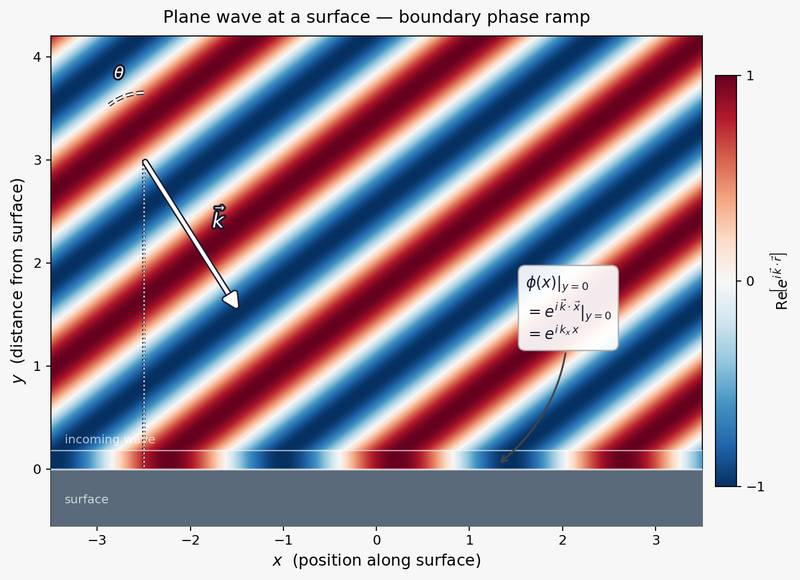

*A plane wave $\text{Re}[e^{i\vec k \cdot \vec r}]$ impinging on a surface at angle $\theta$.*  
*At the boundary ($y=0$) the full 2-D wave reduces to a 1-D phase ramp $e^{ik_x x}$.*  
*Because the position $x$ is stored in binary, this phase ramp factors into one single-qubit gate per qubit — exactly what we implement below.*
</div>

## 6. Steering the Beam — Qubit-Wise Phase Gate

### Why we need a phase ramp

After the QFT the probability of measuring outcome $k$ is $|\hat{A}(k)|^2$.
Without any modification, the central fringe of the diffraction pattern would appear at $k = 0$ — the DC component, which sits at the very edge of our 32-point register and wraps awkwardly.
To place the bright central fringe at the *middle* of the register (position $k_0 = 16$) we use a standard optics trick: multiplying the aperture function by a **linear phase ramp** before the Fourier transform shifts the output spectrum by exactly $k_0$:

$$A(x) \;\longrightarrow\; A(x)\,e^{i \frac{2\pi k_0}{N} x}, \qquad \mathcal{F}\!\left\{A(x)\,e^{i \frac{2\pi k_0}{N} x}\right\}(k) = \hat{A}(k - k_0)$$

For $N = 32$ and $k_0 = 16$ the exponent simplifies to $e^{i\pi x}$.

### Factorizing the phase ramp

At first glance, applying $e^{i\pi x}$ to a quantum state sounds like it requires touching all $2^n = 32$ basis states individually — an exponential number of operations.
But a `QuantumFloat` stores $x$ in binary using $n$ qubits:

$$x = \sum_{i=0}^{n-1} 2^i\, x_i, \qquad x_i \in \{0, 1\}$$

Substituting this into the phase factor:

$$e^{i\pi x} = e^{i\pi \sum_{i} 2^i x_i} = \prod_{i=0}^{n-1} e^{i\pi \cdot 2^i \cdot x_i}$$

Because each factor in this product depends on a **single qubit** $x_i$, the full $n$-qubit phase ramp is equivalent to applying **one single-qubit gate per qubit** — $n$ gates total instead of $2^n$.  This is the key: the binary structure of the register lets us decompose a seemingly complicated operation into a limited number of single qubit gates.

### The single-qubit gate

The [`p(θ, qubit)`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.p.html) gate (**phase gate**) acts as:

$$p(\theta)|0\rangle = |0\rangle, \qquad p(\theta)|1\rangle = e^{i\theta}|1\rangle$$

So applying `p(θ_i, qf[i])` to qubit $i$ contributes $e^{i\theta_i}$ when $x_i = 1$ and does nothing when $x_i = 0$ — implementing exactly the factor $e^{i\theta_i x_i}$.

### Deriving the angle for qubit $i$

For a general target peak `translation` $= t$ in a register of size $N = 2^n$:

$$e^{i \frac{2\pi t}{N} x} = \prod_{i=0}^{n-1} e^{i \frac{2\pi t}{2^n} \cdot 2^i \cdot x_i} = \prod_{i=0}^{n-1} e^{i \cdot t\pi \cdot 2^{i-(n-1)} \cdot x_i}$$

The angle for qubit $i$ is therefore:

$$\boxed{\theta_i = t \cdot \pi \cdot 2^{\,i - (n-1)}}$$

- The **most-significant qubit** ($i = n-1$) gets angle $t\pi$ — the largest rotation.
- The **least-significant qubit** ($i = 0$) gets angle $t\pi / 2^{n-1}$ — a tiny rotation.

For `translation = 16`, `n = 5` the angles are $16\pi, 8\pi, 4\pi, 2\pi, \pi$ going from qubit 4 down to qubit 0 (all but the last are multiples of $2\pi$, so for this translation the whole ramp is a single $\pi$ phase on qubit 0, i.e. a $Z$ gate).

### Guided step: apply the phase ramp

The derivation above gives you the formula directly — this step is about translating the math into code rather than designing new logic. Fill in the loop that applies a `p(...)` gate to each qubit of `qf`.

In [ ]:
translation = 16   # target peak position in Fourier space

# TO-DO
# Apply p(angle, qf[i]) for each qubit index i = 0, 1, ..., qf.size - 1.
# The angle for qubit i is:  translation * np.pi * 2**(i - qf.size + 1)
# Hint: iterate over range(qf.size) and apply the gate to qf[i].

print(f"Phase ramp applied — peak will appear at k = {translation} after QFT.")

## 7. Far-Field Diffraction — [Quantum Fourier Transform](https://www.qrisp.eu/reference/Primitives/QFT.html)

The **[Quantum Fourier Transform](https://www.qrisp.eu/reference/Primitives/QFT.html)** maps position amplitudes to spatial-frequency amplitudes:

$$\text{QFT}|x\rangle = \frac{1}{\sqrt{N}} \sum_{k=0}^{N-1} e^{i 2\pi k x / N} |k\rangle$$

The Fraunhofer sum from the introduction has the opposite sign in the exponent, $e^{-i 2\pi k x / N}$. That is the kernel of the **inverse** QFT, so we call `QFT(qf, inv=True)`.
Applied to our phase-ramped slit state the amplitude for outcome $k$ becomes:

$$\alpha_k = \frac{1}{\sqrt{N}} \sum_{x \in \text{slits}} e^{-i 2\pi k x / N} \cdot e^{i \pi t x / 2^{n-1}} = \frac{1}{\sqrt{N}} \sum_{x \in \text{slits}} e^{-i 2\pi (k - t) x / N}$$

This is the **discrete Fourier transform of the aperture function**, centred at $k = t$ — exactly the Fraunhofer integral.
Measuring the register samples from $P(k) = |\alpha_k|^2$, which is the **intensity pattern on the screen**.

In Qrisp, the QFT is a single function call.

In [ ]:
# Apply the inverse Quantum Fourier Transform — this is the far-field diffraction step.
QFT(qf, inv=True)

# Measure and display.  plot=True shows a bar chart inline.
print("Interference pattern (measurement probabilities):")
qf.get_measurement(plot=True)

## 8. Putting It All Together

Collect every step into a single helper function so you can run experiments in one call.

In [ ]:
def run_double_slit(slits: list[tuple[int, int]], translation: int = 16, n_qubits: int = 5) -> Mapping:
    """
    Full double-slit simulation pipeline.

    Parameters
    ----------
    slits       : list of (lower, upper) tuples
    translation : int   — target peak in Fourier space; default centres the pattern
    n_qubits    : int   — register size (N = 2**n_qubits grid points)
    """
    N = 2**n_qubits
    M = sum(upper - lower for lower, upper in slits)

    # Step 1: define oracle and prepare slit state
    def oracle(qf: QuantumFloat, phase: float) -> None:
        slit_oracle(qf, slits, phase)

    qf = QuantumFloat(n_qubits)
    grovers_alg(qf, oracle, winner_state_amount=M, exact=True)

    # Step 2: steer the beam
    for i in range(qf.size):
        p(translation * np.pi * 2 ** (i - qf.size + 1), qf[i])

    # Step 3: far-field via QFT
    QFT(qf, inv=True)

    # Collect and plot
    raw = qf.get_measurement()
    probs = np.array([raw.get(k, 0.0) for k in range(N)])

    # Centre the x-axis around zero for a symmetric display
    k_axis  = np.arange(N) - N // 2
    probs_c = np.roll(probs, -translation + N // 2)

    plt.figure(figsize=(10, 3))
    plt.bar(k_axis, probs_c, width=0.8, color="steelblue")
    plt.xlabel("Spatial frequency $k$ (centred)")
    plt.ylabel("Probability")
    plt.title(f"Interference pattern — slits={slits}, peak at {translation}")
    plt.tight_layout()
    plt.show()

    return raw

## 9. Exploration

Try the experiments below and observe how the interference pattern changes.

| Experiment | What to expect |
|---|---|
| **Narrow slits** | Wide single-slit envelope (more diffraction), same fringe spacing |
| **Wide slit separation** | Fringes move closer together (smaller period) |
| **Single slit** | No interference fringes — only a smooth diffraction envelope |

Change the `slits` or `translation` and rerun to explore further.

In [ ]:
# Original setup from the tutorial
run_double_slit(slits=[(13, 16), (18, 21)], translation=16)

# Narrow slits — stronger diffraction broadening of each slit's envelope
run_double_slit(slits=[(14, 15), (19, 20)], translation=16)

# Wide slit separation — fringes pack more tightly
run_double_slit(slits=[(8, 11), (22, 25)], translation=16)

# Single slit — no inter-slit interference, only single-slit diffraction
run_double_slit(slits=[(13, 19)], translation=16)

## 10. Bonus: Optimizing the Oracle

### The cost of comparisons

Our `slit_oracle` from §4 works correctly, but it is expensive under the hood:
each `>=` and `<` comparison decomposes into two calls of quantum adders respectively, the De Morgan OR adds more,
and `@auto_uncompute` must reverse *all* of that work to clean up the ancilla qubits.
For a 5-qubit register a single call to the original oracle easily generates **hundreds of CX gates**.

Can we do better?

### Exploiting binary structure

The key idea: **choose slit positions that align to power-of-two boundaries.**
If every position inside a slit shares the same *upper* $k$ bits, then the question
"is $x$ inside this slit?" reduces to checking only those $k$ bits — the lower $n - k$ bits are free to take *any* value.

For $n = 5$ qubits and $k = 3$ upper bits, the register stores

$$x = \underbrace{x_0 \cdot 1 + x_1 \cdot 2}_{\text{lower } n{-}k = 2 \text{ bits}} \;+\; \underbrace{x_2 \cdot 4 + x_3 \cdot 8 + x_4 \cdot 16}_{\text{upper } k = 3 \text{ bits}}$$

Each combination of upper bits selects a **block** of $2^{n-k} = 4$ consecutive positions.
The table below shows all eight blocks and which ones fall inside our slits:

| Upper bits `qf[2] qf[3] qf[4]` | Contribution | Position range | Tagged? |
|:---:|:---:|:---:|:---:|
| `0  0  0` | 0 | 0 – 3 | — |
| `1  0  0` | 4 | 4 – 7 | — |
| `0  1  0` | 8 | 8 – 11 | — |
| **`1  1  0`** | **12** | **12 – 15** | **✓ Slit 1** |
| `0  0  1` | 16 | 16 – 19 | — |
| **`1  0  1`** | **20** | **20 – 23** | **✓ Slit 2** |
| `0  1  1` | 24 | 24 – 27 | — |
| `1  1  1` | 28 | 28 – 31 | — |

Slit 1 occupies positions 12–15 (upper bits `110`) and slit 2 occupies positions 20–23 (upper bits `101`).
Within each slit the lower 2 bits run through all four values `00, 01, 10, 11` — **no position is excluded**, so checking the upper bits alone is sufficient to identify the slit.

### The [`mcp`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.mcp.html) gate — Multi-Controlled Phase

[`mcp(phi, qubits, ctrl_state)`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.mcp.html) applies a phase $e^{i\phi}$ to every computational-basis state
where the qubits match `ctrl_state`, and does nothing to all other states.

Think of it as the "phase version" of [`mcx`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.mcx.html):

| Gate | What it does when the control pattern matches | Extra qubit needed? |
|:---|:---|:---:|
| `mcx(controls, target, ctrl_state)` | **Flips** the target qubit | Yes — requires a target qubit |
| `mcp(phi, qubits, ctrl_state)` | **Shifts the phase** of the amplitude by $e^{i\phi}$ | **No** |

For example:

```python
mcp(phase, qf[-k:], ctrl_state="000")   # tags all positions 0 to 3 at once
```

`qf[-k:]` selects the upper $k = 3$ qubits (indices 2, 3, 4), and the `ctrl_state` string tells the gate which bit pattern to match — character $i$ of the string corresponds to qubit $i$ in the list.

### Do we still need uncomputation?

Recall that the original oracle:

1. **Creates** `QuantumBool` ancilla qubits (from comparisons and the OR reduction).
2. These ancillae become **entangled** with the position register.
3. `@auto_uncompute` must **reverse** all that work to disentangle them.

The `mcp`-based oracle avoids this entirely.
It applies a phase *directly* to the qubits that already encode the position — **no auxiliary qubits are ever created**, so there is nothing to uncompute.

In circuit language, `mcp` is a **diagonal gate**: it multiplies each computational-basis amplitude by a phase factor, without ever creating new superpositions or entanglement between registers.
Because nothing is created, nothing needs to be cleaned up.

### Exercise: Optimized oracle

Implement `optimized_slit_oracle(qf, phase)` for the slit geometry `[(12, 16), (20, 24)]` using two `mcp` calls.

**Hints:**
- `qf[-k:]` with `k = 3` gives you the upper 3 qubits.
- From the table above, slit 1 (positions 12–15) has upper bits `"110"` and slit 2 (positions 20–23) has upper bits `"101"`.
- No `@auto_uncompute` decorator is needed!

In [ ]:
def optimized_slit_oracle(qf: QuantumFloat, phase: float) -> None:
    """
    Phase-tags slit positions using binary structure instead of comparisons.

    Slit geometry: [(12, 16), (20, 24)]
      - Slit 1: positions 12–15  (upper 3 bits = "110")
      - Slit 2: positions 20–23  (upper 3 bits = "101")
    """
    k = 3

    # TO-DO
    # Use mcp(phase, qubits, ctrl_state=...) to tag each slit.
    # Remember: qf[-k:] selects the upper k qubits.
    pass

In [ ]:
# --- Test: verify the optimized oracle produces the correct slit state ---
opt_slits = [(12, 16), (20, 24)]
opt_M = sum(hi - lo for lo, hi in opt_slits)  # 8 winner states

qf_opt = QuantumFloat(5)
grovers_alg(qf_opt, optimized_slit_oracle, winner_state_amount=opt_M, exact=True)

print("Slit state from optimized oracle:")
print(qf_opt)

# Check: should be uniform over {12,13,14,15, 20,21,22,23}
opt_result = qf_opt.get_measurement()
expected_positions = set()
for lo, hi in opt_slits:
    expected_positions.update(range(lo, hi))
print(f"\nExpected positions: {sorted(expected_positions)}")
print(f"Got positions:      {sorted(opt_result.keys())}")
assert set(opt_result.keys()) == expected_positions, "Mismatch — check your ctrl_state strings!"
print("✓ Optimized oracle works correctly!")

### Resource comparison

Let's measure the circuit cost of both oracles on the *same* slit geometry `[(12, 16), (20, 24)]`.

Qrisp lets you compile a quantum session to a low-level circuit and count the gates:

```python
qf.qs.compile().transpile().count_ops()
```

Run the cell below to see the difference. Pay particular attention to the **CX gate count** — this is the dominant cost on real hardware.

In [ ]:
# --- Compare circuit resources: original vs optimized oracle ---
compare_slits = [(12, 16), (20, 24)]
compare_M = sum(hi - lo for lo, hi in compare_slits)

# 1) Original oracle
qf_orig = QuantumFloat(5)

def orig_oracle(qf: QuantumFloat, phase: float) -> None:
    slit_oracle(qf, compare_slits, phase)

grovers_alg(qf_orig, orig_oracle, winner_state_amount=compare_M, exact=True)
orig_ops = qf_orig.qs.compile().transpile().count_ops()

# 2) Optimized oracle
qf_fast = QuantumFloat(5)
grovers_alg(qf_fast, optimized_slit_oracle, winner_state_amount=compare_M, exact=True)
fast_ops = qf_fast.qs.compile().transpile().count_ops()

# Display results
print("=" * 50)
print("ORIGINAL oracle gate counts:")
for gate, count in sorted(orig_ops.items()):
    print(f"  {gate:8s}: {count}")

print(f"\n{'=' * 50}")
print("OPTIMIZED oracle gate counts:")
for gate, count in sorted(fast_ops.items()):
    print(f"  {gate:8s}: {count}")

orig_cx = orig_ops.get("cx", 0)
fast_cx = fast_ops.get("cx", 0)
print(f"\n{'=' * 50}")
print(f"CX gate reduction: {orig_cx} → {fast_cx}  ({orig_cx / max(fast_cx, 1):.1f}× fewer)")

In [ ]:
# --- Run the full simulation with the optimized oracle ---
# Reuse the run_double_slit helper but swap in the optimized oracle.

def run_optimized_double_slit(translation: int = 16, n_qubits: int = 5) -> Mapping:
    """Full pipeline using the optimized oracle."""
    N = 2**n_qubits
    M = 8  # 4 positions per slit × 2 slits

    qf = QuantumFloat(n_qubits)
    grovers_alg(qf, optimized_slit_oracle, winner_state_amount=M, exact=True)

    for i in range(qf.size):
        p(translation * np.pi * 2 ** (i - qf.size + 1), qf[i])

    QFT(qf, inv=True)

    raw = qf.get_measurement()
    probs = np.array([raw.get(k, 0.0) for k in range(N)])
    k_axis = np.arange(N) - N // 2
    probs_c = np.roll(probs, -translation + N // 2)

    plt.figure(figsize=(10, 3))
    plt.bar(k_axis, probs_c, width=0.8, color="steelblue")
    plt.xlabel("Spatial frequency $k$ (centred)")
    plt.ylabel("Probability")
    plt.title("Interference pattern — optimized oracle, slits=[(12,16),(20,24)]")
    plt.tight_layout()
    plt.show()
    return raw

print("Same physics, a fraction of the gates:")
run_optimized_double_slit()

## 11. Bonus: Build Your Own Grover

So far [`grovers_alg`](https://www.qrisp.eu/reference/Algorithms/Grover.html) has done the heavy lifting.
Look at how you called it: you passed your oracle *function* as an argument, and `grovers_alg` called it in every iteration.
A function that takes other functions as arguments is a **higher-order function**.
Quantum functions in Qrisp are ordinary Python functions, so you can pass them around like any other value.
In this bonus you write the two remaining pieces yourself: the **diffuser**, and the Grover loop that ties oracle and diffuser together.

### The diffuser is a conjugation

The diffuser reflects the state about the uniform superposition $|s\rangle = H^{\otimes n}|0\rangle$.
Reflecting about $|0\rangle$ is easy: it only needs a phase on the all-zero state.
Reflecting about $|s\rangle$ is one change of basis away:

1. map $|s\rangle$ to $|0\rangle$ with a layer of Hadamard gates,
2. apply the phase $e^{i\phi}$ to $|0\rangle$ only,
3. undo the Hadamard layer.

$$D(\phi) \;=\; H^{\otimes n}\,\bigl(\mathbb{1} + (e^{i\phi} - 1)\,|0\rangle\langle 0|\bigr)\,H^{\otimes n} \;=\; \mathbb{1} + (e^{i\phi} - 1)\,|s\rangle\langle s|$$

For $\phi = \pi$ this is the textbook diffuser $2|s\rangle\langle s| - \mathbb{1}$ up to a global sign; exact Grover passes its tuned $\phi$ instead.

The "apply $V$, act, undo $V$" pattern $V^\dagger U V$ shows up all over quantum computing: adders, diffusers, basis changes, block encodings.
Qrisp has a dedicated environment for it, [`conjugate`](https://www.qrisp.eu/reference/Quantum%20Environments/ConjugationEnvironment.html):

```python
with conjugate(V)(args):
    ...   # the block U
```

runs `V(args)`, then the block, then the inverse of `V(args)`, which Qrisp generates for you.
`conjugate` is itself a higher-order function: it takes the quantum function `V` as its argument.

For step 2 you can reuse [`mcp`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.mcp.html) from section 10.
An integer `ctrl_state` is read as a value of the register, so `mcp(phase, qf, ctrl_state=0)` puts the phase on $|0\rangle$ and nowhere else.

### Exercise: `my_diffuser`

Implement `my_diffuser(qf, phase)` with a `conjugate` environment: the Hadamard gate [`h`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.h.html) is the conjugator $V$, and the phase on $|0\rangle$ is the block.
Two lines are enough.

In [ ]:
def my_diffuser(qf: QuantumFloat, phase: float = np.pi) -> None:
    """
    Reflects qf about the uniform superposition |s>.

    Parameters
    ----------
    qf    : QuantumFloat — the register to reflect
    phase : float        — phase applied to the |s> component (np.pi gives the standard diffuser)
    """

    # TO-DO
    # 1. Open a conjugate environment with the Hadamard gate h as the conjugator.
    # 2. Inside it, apply `phase` to the all-zero state with mcp.

    pass

In [ ]:
# --- Test my_diffuser ---
# One Grover iteration by hand: flip the sign of position 5, then diffuse.
# Your diffuser must amplify position 5 exactly like Qrisp's built-in diffuser.
from qrisp.grover import diffuser as qrisp_diffuser

def one_iteration(diffuser_fn: Callable[[QuantumFloat], None]) -> Mapping:
    qf_it = QuantumFloat(5)
    h(qf_it)
    mcp(np.pi, qf_it, ctrl_state=5)   # oracle: sign flip on |5>
    diffuser_fn(qf_it)
    return qf_it.get_measurement()

mine = one_iteration(my_diffuser)
reference = one_iteration(qrisp_diffuser)

print(f"P(5) before: {1 / 32:.3f}   after my_diffuser: {mine.get(5, 0):.3f}   after Qrisp's diffuser: {reference.get(5, 0):.3f}")
if all(abs(mine.get(x, 0) - reference.get(x, 0)) < 1e-3 for x in range(32)):
    print("Congratulations! my_diffuser works correctly.")
else:
    print("Something is wrong: the distribution differs from Qrisp's diffuser.")

### Exercise: `my_grovers_alg`

Now write the higher-order function itself.
`my_grovers_alg` receives the **oracle and the diffuser as arguments**.
It does not care how either of them is implemented, as long as both accept `(qf, phase)`.
The iteration count $k$ and the phase $\phi$ are already computed with the formulas from section 5. Your part is the algorithm:

1. put `qf` into uniform superposition,
2. repeat $k$ times: apply the oracle, then the diffuser, both with `phase=phi`.

The test below plugs in both oracles you wrote (section 4 and section 10) and Qrisp's built-in diffuser next to yours.

In [ ]:
def my_grovers_alg(
    qf: QuantumFloat,
    oracle: Callable[[QuantumFloat, float], None],
    diffuser: Callable[[QuantumFloat, float], None],
    winner_state_amount: int,
) -> None:
    """
    Exact Grover search as a higher-order function.

    Parameters
    ----------
    qf                  : QuantumFloat — the search register
    oracle              : function (qf, phase) — phase-tags the winner states
    diffuser            : function (qf, phase) — reflection about the uniform superposition
    winner_state_amount : int — number of winner states M
    """
    N = 2**qf.size
    theta = np.arcsin(np.sqrt(winner_state_amount / N))
    k = int(np.ceil(np.pi / (4 * theta) - 0.5))                                          # number of iterations
    phi = 2 * np.arcsin(np.sin(np.pi / (4 * k + 2)) * np.sqrt(N / winner_state_amount))  # exact-Grover phase

    # TO-DO
    # 1. Put qf into uniform superposition.
    # 2. Repeat k times: call the oracle, then the diffuser, both with phase=phi.

    pass

In [ ]:
# --- Test my_grovers_alg: mix and match oracles and diffusers ---
# Any oracle works with any diffuser, as long as both accept (qf, phase).
from qrisp.grover import diffuser as qrisp_diffuser

def section4_oracle(qf: QuantumFloat, phase: float) -> None:   # the comparison-based oracle from section 4
    slit_oracle(qf, [(13, 16), (18, 21)], phase)

experiments = [
    ("section 4 oracle  + my_diffuser   ", section4_oracle,       my_diffuser,    [(13, 16), (18, 21)]),
    ("section 10 oracle + my_diffuser   ", optimized_slit_oracle, my_diffuser,    [(12, 16), (20, 24)]),
    ("section 10 oracle + Qrisp diffuser", optimized_slit_oracle, qrisp_diffuser, [(12, 16), (20, 24)]),
]

all_ok = True
for name, oracle_fn, diffuser_fn, exp_slits in experiments:
    expected = {x for lo, hi in exp_slits for x in range(lo, hi)}
    qf_mix = QuantumFloat(5)
    my_grovers_alg(qf_mix, oracle_fn, diffuser_fn, winner_state_amount=len(expected))
    meas = qf_mix.get_measurement()
    ok = set(meas) == expected and all(abs(prob - 1 / len(expected)) < 1e-3 for prob in meas.values())
    all_ok = all_ok and ok
    print(f"{'✓' if ok else '✗'} {name}: {sorted(meas)}")

if all_ok:
    print("\nCongratulations! my_grovers_alg works with every oracle/diffuser combination.")
else:
    print("\nSomething is wrong: every combination should give a uniform superposition over its slit positions.")

### What Qrisp does under the hood

Your `my_diffuser` is essentially Qrisp's own implementation: [`reflection.py`](https://github.com/eclipse-qrisp/Qrisp/blob/main/src/qrisp/alg_primitives/reflection.py) also wraps `mcp(phase, qubits, ctrl_state=0)` in a `conjugate` environment, plus a global phase.

Qrisp's [`diffuser`](https://www.qrisp.eu/reference/Primitives/generated/qrisp.grover.diffuser.html) goes one step further and is a higher-order function itself: its `state_function` argument takes any state-preparation function and reflects about the state that function prepares instead of $|s\rangle$.
Start the algorithm from that same state and Grover's algorithm becomes [amplitude amplification](https://www.qrisp.eu/reference/Primitives/amplitude_amplification.html).
This is also where the automatically generated inverse pays off: for $V = H^{\otimes n}$ it is trivial because $H$ is its own inverse, but for a general state preparation Qrisp derives $V^\dagger$ for you.

## Summary

| Step | Physics | Qrisp code |
|---|---|---|
| **Position register** | Discrete position grid $x = 0 \ldots N{-}1$ | `QuantumFloat(n)` |
| **Slit test** | Is $x$ inside the slit? | `is_in_slit(qf, slit)` using `>=`, `<`, `mcx` |
| **OR across slits** | Is $x$ inside *any* slit? | De Morgan: `mcx(..., ctrl_state=0)` + `flip()` |
| **Uncomputation** | Erase which-path info → restore coherence | `@auto_uncompute` |
| **Slit state** | $\frac{1}{\sqrt{M}}\sum_{x\in\text{slits}}|x\rangle$ | `grovers_alg(..., exact=True)` |
| **Beam steering** | Phase ramp $e^{ik_0 x}$ shifts the pattern | qubit-wise `p(...)` |
| **Far field** | Fraunhofer diffraction $\hat{A}(k)$ | `QFT(qf, inv=True)` |
| **Intensity** | $P(k) = |\hat{A}(k)|^2$ | `qf.get_measurement()` |
| **Optimized oracle** | Binary-aligned slits → direct phase tagging | `mcp(phase, qf[-k:], ctrl_state=...)` |
| **Diffuser** | Reflection about the uniform superposition | `with conjugate(h)(qf): mcp(phase, qf, ctrl_state=0)` |
| **Grover loop** | Any oracle with any diffuser | higher-order `my_grovers_alg(qf, oracle, diffuser, M)` |